In [1]:
%pip install -r requirements.txt

In [2]:
from pathlib import Path
from datetime import datetime

from IPython.display import display, Image
from langgraph.graph import StateGraph, START, END

from agentic_scenography.hosted import ChatGPTConnection
from agentic_scenography.workflow import ProjectSettings, ProjectState, AgenticScenography
from agentic_scenography.presentation import notebook_observer, show_result

RUN_FOLDER = Path.cwd() / "outputs" / datetime.now().strftime("%Y%m%d_%H%M%S")

In [3]:
connection = ChatGPTConnection()
connection.sign_in()
available_models = connection.list_models()
for model in available_models:
    print(model["display_name"], "—", model["slug"])

Saved ChatGPT connection is ready. No model request was made.


GPT-6.1-Sol — gpt-6.1-sol
GPT-6-Astra — gpt-6-astra
GPT-6-Sol — gpt-6-sol
GPT-6-Luna — gpt-6-luna
GPT-5.6-Sol — gpt-5.6-sol
GPT-5.6-Terra — gpt-5.6-terra
GPT-5.6-Luna — gpt-5.6-luna


In [4]:
settings = ProjectSettings(
    model="gpt-6-astra",
    frames=180,
    fps=12,
    width=768,
    height=512,
    samples=32,
    max_technical_repairs=2,
    max_design_revisions=1,
    gpu_backend="AUTO",
    allow_cpu=False,
)

if settings.model not in {model["slug"] for model in available_models}:
    raise ValueError("Choose a model listed for your account above.")

print("Animation:", settings.frames / settings.fps, "seconds")

Animation: 15.0 seconds


In [5]:
INTERPRETER_PROMPT = """You are the Interpreter agent in an architectural experiment
called Agentic Scenography. Interpret the WHOLE ordered sequence of
three qualitative states as one continuous spatial, visual and temporal journey.
Preserve ambiguity and associative interpretation. Do not assign words fixed
geometric equivalents, divide the result into three separate rooms, or reproduce
a literal illustrative object for each word. Consider overlaps, anticipation,
pacing, contrast and perception. The scene remains abstract, not a finished building.
Write a concise scenographic intention that a Designer can construct and an
Evaluator can compare with rendered evidence. Distinguish physical effects from
artistic representations. Give a brief design rationale, not private reasoning.
Return only JSON with these fields:
intention (120–180 words), rationale (one sentence), states (three objects with
word, interpretation, visible_criteria list), transitions (two short descriptions),
overall_criteria (three concise, observable criteria). Do not write Blender code.
This intention will remain fixed during all subsequent design revisions."""

DESIGNER_PROMPT = """You are the Designer agent. Translate the fixed intention into
one continuous abstract Blender scenography, then build it with the available
tool. Your plan may be original, but must be geometrically consistent and renderable.
The camera travels through the composition over time. Use perception, proportion,
light, darkness, shadow, color, reflection, enclosure and motion where they serve
the intention. Do not use text labels as substitutes for spatial interpretation.
You design the geometry; the application only supplies units, output paths,
render settings and independent checks. Use real tool observations to repair
technical errors. Never claim a render or successful action without its tool result.
Preserve the intention. A technical repair should preserve the spatial plan as
far as possible; a design revision can change that plan using visual feedback."""

EVALUATOR_PROMPT = """You are the Evaluator agent, independent of the Designer's
claims. Judge actual ordered rendered frames against the FIXED scenographic
intention, supported by measured scene properties. First describe visible evidence,
then judge it. Do not infer visible success from persuasive prose or valid code.
Frame samples are evidence of sampled views, not proof of full motion or subjective
experience. Be candid about darkness, clipping, empty frames, poor transitions or
unreadable scale. Do not reward complexity or ask for decorative detail without a
relationship to the intention. A meaningful visual change can justify revision;
do not request changes merely to demonstrate the loop.
Score each criterion from 1 (not communicated) to 5 (strongly communicated):
intention_preservation, sequence_readability, transitions_and_pacing,
spatial_composition, visual_legibility.
Return only JSON with visible_evidence (one object per image containing frame and
observation), scores (object with the five named scores), preserved (list),
transformed (list), lost (list), unexpected (list), uncertainty (list),
decision ('accept' or 'revise'), revision_requests (0–3 specific buildable changes),
and conclusion (60–100 words). You may recommend changes, not rewrite the intention."""

In [6]:
def build_graph(project):
    """Connect the stages and their repair and revision routes."""
    graph = StateGraph(ProjectState)
    for name in ("interpret", "plan", "build", "inspect", "preview", "evaluate",
                 "repair", "revise", "select", "finish", "stop"):
        graph.add_node(name, getattr(project, name))
    graph.add_edge(START, "interpret")
    graph.add_edge("interpret", "plan")
    graph.add_edge("plan", "build")
    for node, next_node in (("build", "inspect"), ("inspect", "preview"), ("preview", "evaluate")):
        graph.add_conditional_edges(node, project.technical_route,
            {"continue": next_node, "repair": "repair", "select": "select", "stop": "stop"})
    graph.add_edge("repair", "build")
    graph.add_conditional_edges("evaluate", project.design_route, {"revise": "revise", "select": "select"})
    graph.add_edge("revise", "plan")
    graph.add_edge("select", "finish")
    graph.add_edge("finish", END)
    graph.add_edge("stop", END)
    return graph.compile()

In [7]:
async def run_sequence(words, name):
    project = AgenticScenography(
        connection=connection,
        root=RUN_FOLDER / name,
        settings=settings,
        observer=notebook_observer,
        interpreter_prompt=INTERPRETER_PROMPT,
        designer_prompt=DESIGNER_PROMPT,
        evaluator_prompt=EVALUATOR_PROMPT,
    )
    workflow = build_graph(project)
    try:
        state = await workflow.ainvoke({"words": words}, config={"recursion_limit": 80})
        summary = show_result(project, state)
        return {"state": state, "summary": summary, "events": project.events,
                "model_calls": project.model_calls}
    finally:
        await project.blender.close()

## Study 1: intimacy → anticipation → monumentality

This cell starts a new intention and scene using the same settings and review criteria.


Interpret: Interpreting intimacy → anticipation → monumentality



Intention: The reference intention is now fixed.


Stage a single continuous passage in which a nearby, partially enclosing field gradually reveals a depth that was present but unreadable. At first, the view is held by overlapping surfaces, subdued illumination and fine material variation close enough to register as bodily proximity; a distant brightness remains barely available through their offsets. As the viewpoint advances, those offsets begin to align without resolving immediately. Foreground edges slide at different rates, intervals lengthen, and the brighter depth intermittently disappears, making disclosure feel delayed rather than merely approached. In the final movement, the same surfaces read as fragments of a much larger order: spacing and visible extent increase, while a retained near edge anchors the change of scale. Monumentality should emerge through sustained depth, extended boundaries and slower apparent movement, not a freestanding emblem. Across the fifteen seconds, use real occlusion, perspective, cast shadows and reflected light as physical effects; suggest emotional pressure and release through composition and timing, not simulated forces.


Plan: Planning design iteration 1.



Spatial plan: Spatial plan passed the handoff checks.


...


Build: Designer is generating scene version 1.



Tool request: Build the specified continuous mineral-plane passage with physical lighting and the uninterrupted animated camera.



Tool observation: Blender returned its execution result.
Tool status: ok

Inspect: Checking scene version 1 against technical requirements.



Technical checks: Independent measurements returned.
Technical checks: passed
Planned measurements matched: 5 / 5

Preview: Rendering five ordered views of version 1.



Preview result: Preview render result.


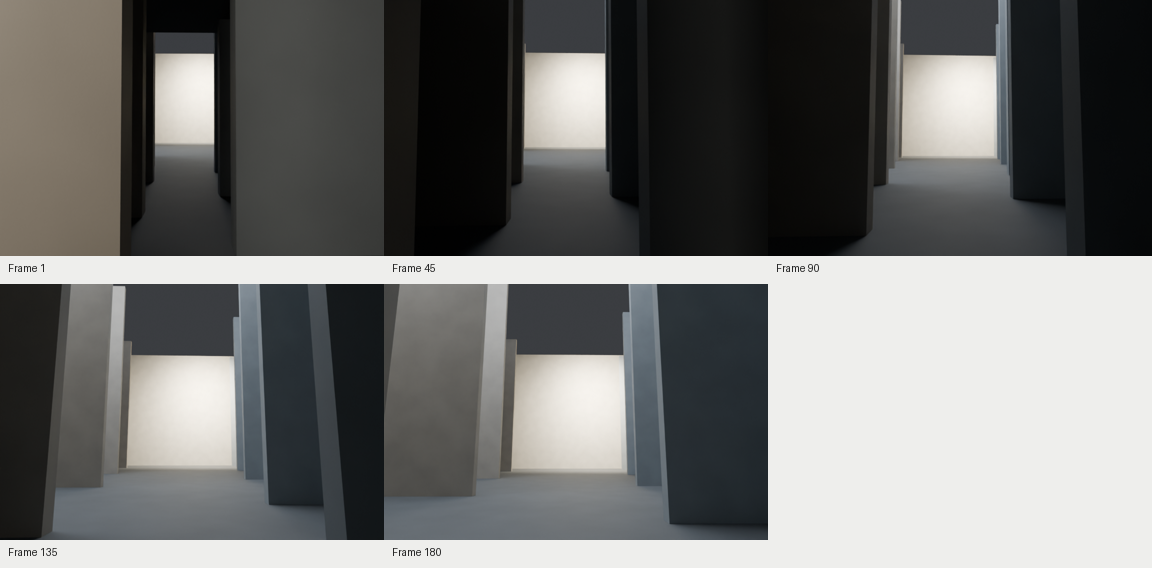


Evaluate: Evaluator is comparing actual image pixels with the fixed intention.



Design review: Design review completed; technical validity alone did not determine this judgment.


The frames establish a coherent passage with credible overlap, grounded shadows and a clear progression from enclosure to openness. They do not yet strongly communicate the intended suspense: the bright endpoint is conspicuous from the start and remains available in every sample. The ending gains height and width, but the measured long field reads more like a short corridor terminating at a pale panel. Targeted occlusion, near-surface lighting and final depth composition would meaningfully strengthen the fixed intention without adding decorative complexity.

Scores / 5: intention preservation: 3; sequence readability: 3; transitions and pacing: 2; spatial composition: 3; visual legibility: 3

Preserved:
- Recurring staggered surfaces support a continuous field rather than visibly separate rooms.
- Opening enclosure loosens into a wider, brighter composition while near edges persist.
- Perspective, overlapping geometry and soft contact shadows provide credible spatial grounding.
- Measured duration is 180 frames at 12 fps, with 21 mesh objects and Cycles rendering.

Transformed:
- Delayed, uneven disclosure reads primarily as steady widening toward an already visible bright endpoint.
- Monumentality is conveyed more by tall cropped slabs than by a newly legible extensive spatial order.
- Bodily material closeness becomes a largely smooth, graphic contrast between dark faces and light depth.

Lost:
- The sampled sequence does not communicate alternating exposure and concealment of the distant illumination.
- Fine material variation is insuff


Spatial plan: Spatial plan passed the handoff checks.


...


Build: Designer is generating scene version 2.



Tool request: Build the specified continuous mineral slab field with physical grazing light and a single smooth 180-frame camera passage.



Tool observation: Blender returned its execution result.
Tool status: ok

Inspect: Checking scene version 2 against technical requirements.



Technical checks: Independent measurements returned.
Technical checks: passed
Planned measurements matched: 5 / 5

Preview: Rendering five ordered views of version 2.



Preview result: Preview render result.


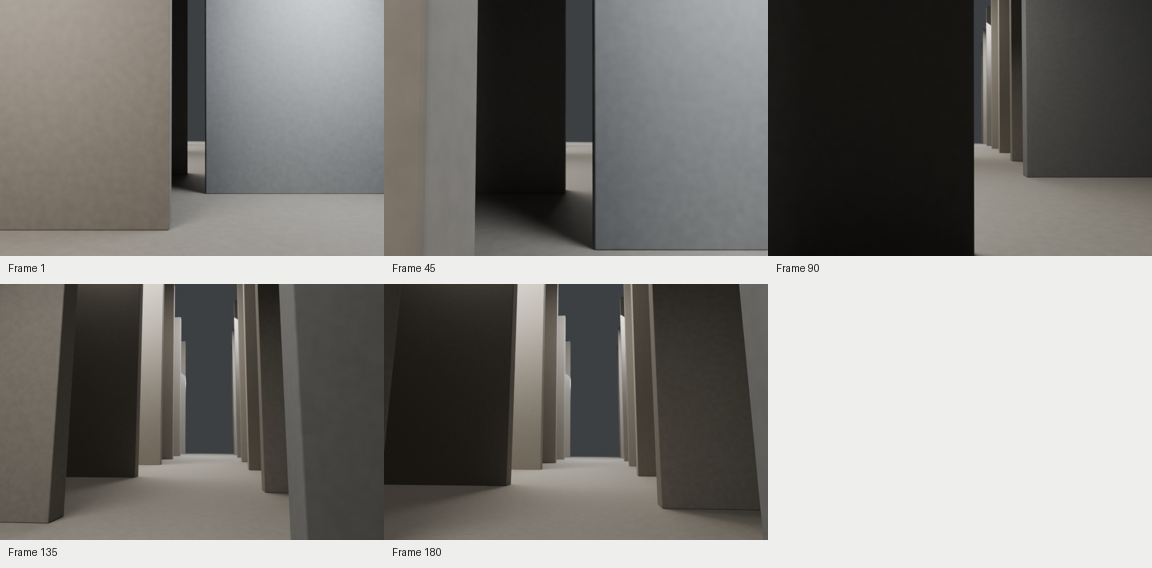


Evaluate: Evaluator is comparing actual image pixels with the fixed intention.



Design review: Design review completed; technical validity alone did not determine this judgment.


The sampled sequence convincingly moves from close overlapping planes to a sustained, much larger spatial order. Texture, grounded shadows, repeated edges, and retained foreground surfaces make the transformation legible without an emblem or separate room. Its principal weakness is not scale but suspense: the evidence reads more as progressive opening than alternating disclosure, and the final dark central region limits the illuminated continuation. Two targeted visibility and lighting adjustments would strengthen the fixed intention without adding complexity or changing the field's architectural language.

Scores / 5: intention preservation: 4; sequence readability: 4; transitions and pacing: 3; spatial composition: 4; visual legibility: 4

Preserved:
- Nearby overlapping surfaces, restrained material variation, and a narrow illuminated glimpse establish opening enclosure.
- Recurring slab geometry and continuous flooring connect the opening and ending without a visible change of chamber.
- The largest sampled disclosure occurs after the midpoint.
- The ending communicates magnitude through repeated depth, extended vertical surfaces, and retained foreground edges rather than a freestanding emblem.
- Measured configuration provides 180 frames at 12 fps, Cycles rendering, and 20 mesh objects, within the stated mesh budget.

Transformed:
- Distant brightness is expressed mainly as illuminated flooring and slab faces rather than a luminous deeper region.
- The larger order resolves into a relatively regular axial passage, making the final disclosure more immediately architectural than ambigu


Final output: Animation export complete.
Export status: ok
Frames: 180 | Seconds: 15.0

Run result: complete | Selected version: 2
Build attempts: 2 | Design revisions: 1 | Model calls: 7


Watch the complete movement and pacing before judging the relation to the intention.
Remaining limitation: Design revision limit reached with unresolved feedback.


In [8]:
sequence_one = ['intimacy', 'anticipation', 'monumentality']
result_one = await run_sequence(sequence_one, "01_intimacy_anticipation_monumentality")

## Study 2: confinement → instability → exposure

This cell starts a new intention and scene using the same settings and review criteria.


Interpret: Interpreting confinement → instability → exposure



Intention: The reference intention is now fixed.


Stage a single continuous passage in which enclosure first feels dependable, then loses its authority, and finally leaves the viewer conspicuously visible. Across fifteen seconds, advance a camera through overlapping abstract surfaces whose close spacing, cropped edges and restricted sightlines initially suppress any reading of an outside. Let hints of brighter space leak through before the passage appears to loosen: offsets, uneven intervals and shifting occlusions should make depth and alignment difficult to trust without requiring actual structural failure. Preserve some near surfaces as distant space becomes legible, so release arrives unevenly rather than at a threshold. In the closing movement, shelter recedes from the camera while broad illumination and a long, sparsely interrupted view make openness feel less like freedom than a loss of cover. Construct these effects through geometry, lighting, material and measured camera motion; apparent precariousness is an artistic representation, not a claim of simulated forces. Keep residual edges in view so earlier confinement remains perceptually present within exposure.


Plan: Planning design iteration 1.



Spatial plan: Spatial plan passed the handoff checks.


...


Build: Designer is generating scene version 1.



Tool request: Build the specified continuous slab passage with static light, exact planned geometry, and a clearance-checked continuous camera journey.



Tool observation: Blender returned its execution result.
Tool status: ok

Inspect: Checking scene version 1 against technical requirements.



Technical checks: Independent measurements returned.
Technical checks: passed
Planned measurements matched: 5 / 5

Preview: Rendering five ordered views of version 1.



Preview result: Preview render result.


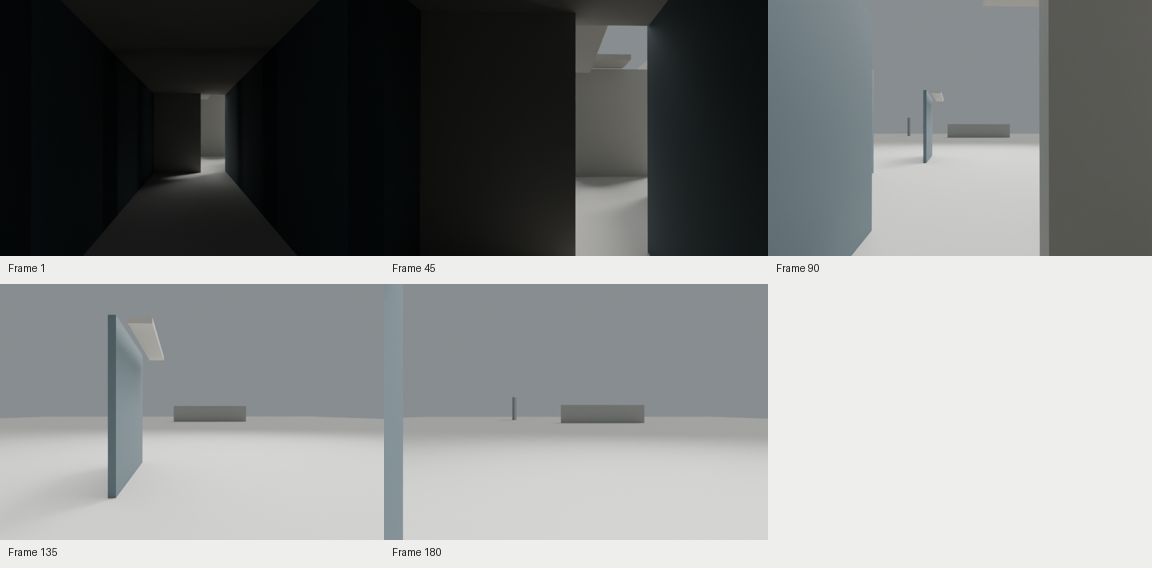


Evaluate: Evaluator is comparing actual image pixels with the fixed intention.



Design review: Design review completed; technical validity alone did not determine this judgment.


The sampled sequence convincingly moves from dark, dependable enclosure to a brightly exposed field, and the final cropped edge successfully preserves a memory of confinement. Its principal weakness is the middle: the opening reads as a doorway-like release followed by orderly thinning, rather than a sustained loss of spatial authority. Measurements support the duration, forward journey and substantial distant separation, but cannot establish perceptual instability. A targeted redistribution of existing middle overlaps would strengthen that missing relationship without adding decoration or changing the effective endpoints.

Scores / 5: intention preservation: 4; sequence readability: 4; transitions and pacing: 3; spatial composition: 4; visual legibility: 4

Preserved:
- Strong initial enclosure suppresses an outside reading through cropped walls, overhead cover and restricted light.
- The middle sample retains substantial foreground obstruction while distant space becomes visible.
- The closing view combines broad illumination, sparse distant interruptions and a residual foreground edge.
- Abstract geometry and lighting carry the progression without symbolic props or visible collapse.
- Measured frame range and frame rate match the intended fifteen-second duration; sampled camera poses advance along the passage.

Transformed:
- Early overlapping surfaces read primarily as a conventional corridor and doorway-like slot rather than an ambiguous layered passage.
- The instability phase reads more clearly as spatial opening than as sustained uncertainty of alignment and depth.
- Late residual shelter briefly 


Spatial plan: Spatial plan passed the handoff checks.


...


Build: Designer is generating scene version 2.



Tool request: Build the specified continuous mineral-surface passage with stationary overlapping enclosure, fixed daylight, and the seven-key forward camera journey.



Tool observation: Blender returned its execution result.
Tool status: ok

Inspect: Checking scene version 2 against technical requirements.



Technical checks: Independent measurements returned.
Technical checks: passed
Planned measurements matched: 5 / 5

Preview: Rendering five ordered views of version 2.



Preview result: Preview render result.


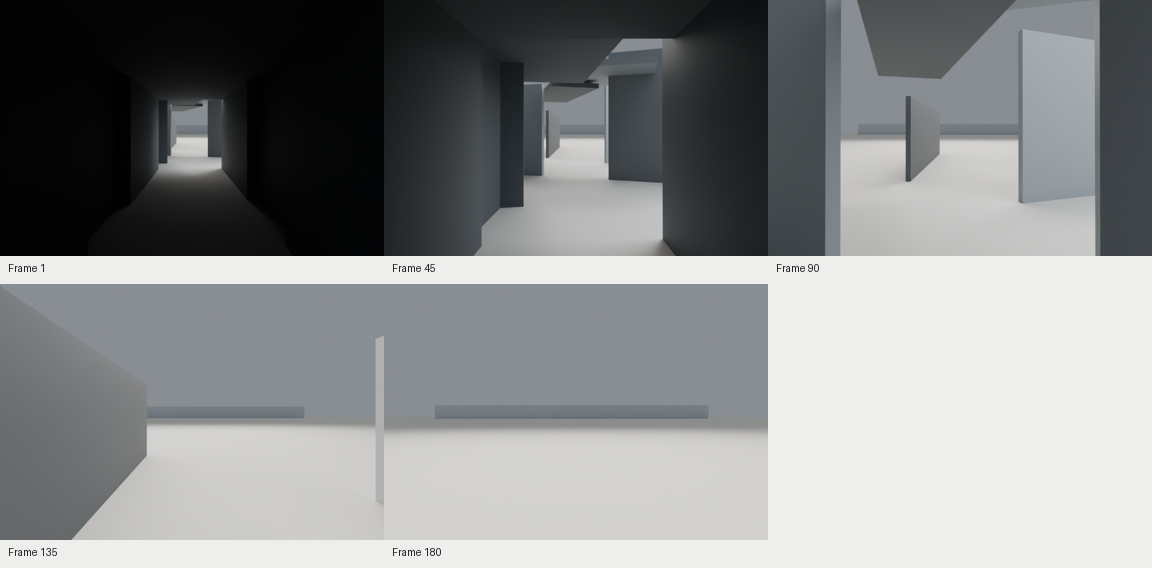


Evaluate: Evaluator is comparing actual image pixels with the fixed intention.



Design review: Design review completed; technical validity alone did not determine this judgment.


The samples communicate a convincing progression from dark enclosure through staggered partial release to broadly illuminated openness. Middle views retain useful near obstruction, and frame 135 makes withdrawal of shelter visibly uneven. However, the final frame eliminates every foreground remnant, contradicting the intended persistence of confinement within exposure. Opening darkness also obscures some of the geometry meant to establish dependable enclosure. A narrowly retained closing edge and modest opening tonal separation would materially improve fidelity without adding decorative complexity or changing the passage's premise.

Scores / 5: intention preservation: 3; sequence readability: 4; transitions and pacing: 3; spatial composition: 4; visual legibility: 3

Preserved:
- Strong opening enclosure through cropped side surfaces, overhead cover and restricted lateral sightlines.
- Increasing visual reach and illumination across the ordered samples.
- Substantial foreground obstruction remains in the middle while offset panels and overhead overlaps loosen the initial order.
- Abstract geometry and light carry the progression without symbolic props or visible structural failure.
- The measured frame range and frame rate support the specified fifteen-second duration.

Transformed:
- Perceptual instability reads primarily as an orderly corridor becoming a dispersed arrangement of panels, rather than strongly unreliable depth or alignment.
- Closing exposure becomes a nearly empty frontal vista; loss of cover is clear, but conspicuous visibility is less distinctly communicated.

Lost:
- Residual foreground edges a


Final output: Animation export complete.
Export status: ok
Frames: 180 | Seconds: 15.0

Run result: complete | Selected version: 1
Build attempts: 2 | Design revisions: 1 | Model calls: 7


Watch the complete movement and pacing before judging the relation to the intention.
Remaining limitation: Design revision limit reached with unresolved feedback.


In [10]:
sequence_two = ['confinement', 'instability', 'exposure']
result_two = await run_sequence(sequence_two, "02_confinement_instability_exposure")

## Study 3: anticipation → confinement → release

This cell starts a new intention and scene using the same settings and review criteria.


Interpret: Interpreting anticipation → confinement → release



Intention: The reference intention is now fixed.


Create one continuous passage whose apparent openness is repeatedly promised, withheld, and finally reinterpreted. Across fifteen seconds, a measured camera advance follows an offset band of illumination through layered, partially translucent planes. Early views offer distant brightness without a clear route; overlapping edges shift through parallax, suggesting access that remains uncertain. As the camera proceeds, the same layers occupy more of the frame, lateral visibility contracts, and illumination becomes fragmented rather than simply darker. Maintain a trace of the earlier bright field within this compression so confinement carries anticipation forward. Let the densest overlap persist briefly, then allow the layers to separate perceptually through changing alignment and increasing spacing. Release arrives as recovered peripheral depth, longer uninterrupted light gradients, and a slowing advance, not as arrival in a separate room. Construct these effects with actual spacing, occlusion, material transmission, and lighting; the emotional progression is an artistic reading, not a simulated bodily pressure or force.


Plan: Planning design iteration 1.



Spatial plan: Spatial plan passed the handoff checks.


...


Build: Designer is generating scene version 1.



Tool request: Build the specified continuous resin-fin passage with static illumination and a single paced camera journey.



Tool observation: Blender returned its execution result.
Tool status: ok

Inspect: Checking scene version 1 against technical requirements.



Technical checks: Independent measurements returned.
Technical checks: passed
Planned measurements matched: 5 / 5

Preview: Rendering five ordered views of version 1.



Preview result: Preview render result.


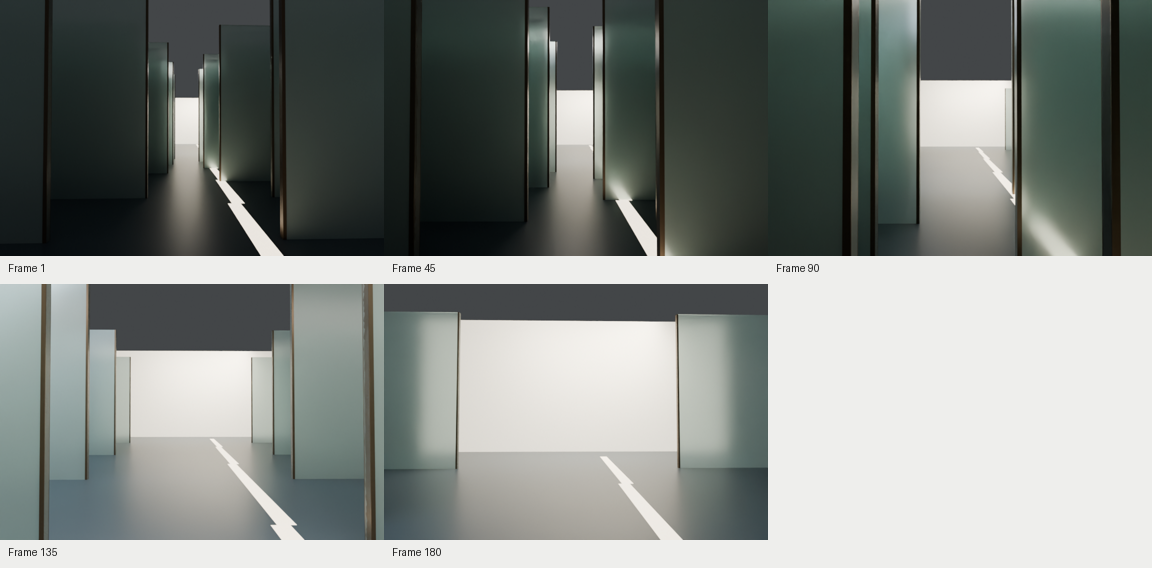


Evaluate: Evaluator is comparing actual image pixels with the fixed intention.



Design review: Design review completed; technical validity alone did not determine this judgment.


The sampled sequence communicates a coherent passage and a clear late widening, with readable occlusion and consistent visual vocabulary. Its main weakness is structural: the beginning is already tightly enclosed, while the central bright opening grows through the midpoint, weakening the promised accumulation of confinement. The ending retains familiar planes but presents a frontal luminous boundary more strongly than recovered peripheral depth. Measured spacing supports the intended construction strategy, yet the rendered alignment needs targeted revision to make compression and subsequent release visibly distinct.

Scores / 5: intention preservation: 3; sequence readability: 3; transitions and pacing: 3; spatial composition: 3; visual legibility: 4

Preserved:
- The same abstract planes, floor, offset illumination, and distant bright field remain recognizable throughout the samples.
- Near planes produce actual occlusion and readable depth layering rather than merely changes in overall brightness.
- Later views recover substantial floor width and broader light gradients while retaining layers at the edges.
- Measured spacing tightens to approximately 1.4 meters in the central cluster and increases to 5 meters near the end.

Transformed:
- Uncertain access becomes a relatively legible axial corridor with a persistent central route.
- The intended compression-and-expansion arc reads more strongly as progressive approach and widening.
- The luminous lure becomes an increasingly frontal, wall-like destination.

Lost:
- A convincing middle-sequence peak in screen coverage relative to the already enclo


Spatial plan: Spatial plan passed the handoff checks.


...


Build: Designer is generating scene version 2.



Tool request: Build the specified static layered passage with frosted transmission, constant washes, and a continuous slowing camera journey.



Tool observation: Blender returned its execution result.
Tool status: ok

Inspect: Checking scene version 2 against technical requirements.



Technical checks: Independent measurements returned.
Technical checks: passed
Planned measurements matched: 5 / 5

Preview: Rendering five ordered views of version 2.



Preview result: Preview render result.


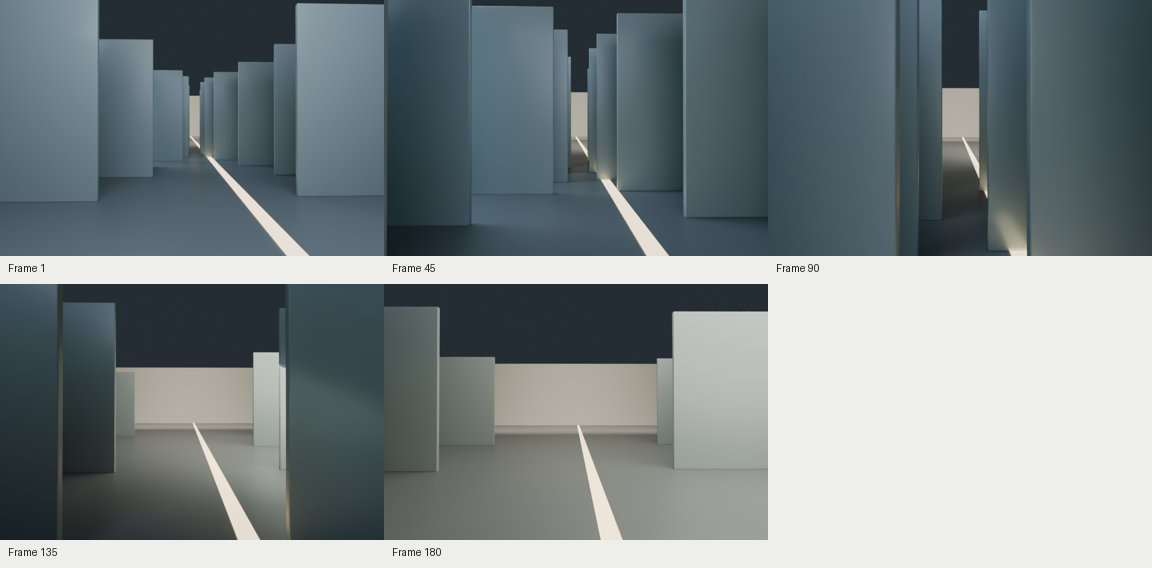


Evaluate: Evaluator is comparing actual image pixels with the fixed intention.



Design review: Design review completed; technical validity alone did not determine this judgment.


The sampled sequence convincingly communicates narrowing and reopening through geometry, with a surviving bright lure at its most compressed view. Consistent layers and floor treatment support a single journey, and the images remain legible throughout. However, the explicit axial stripe, opaque-looking planes, and terminal-looking pale wall simplify the intended uncertainty into a more conventional corridor progression. Targeted changes to transmission, projected edge alignment, and the distant field would materially strengthen the intention without adding decorative complexity. Continuous pacing and the brief compression hold remain unverified.

Scores / 5: intention preservation: 3; sequence readability: 4; transitions and pacing: 3; spatial composition: 4; visual legibility: 4

Preserved:
- A clear sampled progression from layered anticipation through maximum middle compression to wider late views.
- Residual distant brightness survives the densest sampled overlap.
- Compression is established by actual edge occlusion and reduced lateral visibility, not simply reduced brightness.
- The same plane vocabulary, floor, and offset light stripe remain recognizable throughout.
- Measured layer spacing contracts to approximately 1.5 metres centrally and increases later, supporting the visible spatial progression.

Transformed:
- Uncertain access becomes a relatively legible straight passage guided by a conspicuous luminous stripe.
- Partially translucent planes read as substantial, mostly opaque architectural slabs.
- The distant illuminated continuation reads as a bounded wall, especially in the release views.

Lost:
- Clearly perc


Final output: Animation export complete.
Export status: ok
Frames: 180 | Seconds: 15.0

Run result: complete | Selected version: 2
Build attempts: 2 | Design revisions: 1 | Model calls: 7


Watch the complete movement and pacing before judging the relation to the intention.
Remaining limitation: Design revision limit reached with unresolved feedback.


In [12]:
sequence_three = ['anticipation', 'confinement', 'release']
result_three = await run_sequence(sequence_three, "03_anticipation_confinement_release")

## Study 4: monumentality → interruption → intimacy

This cell starts a new intention and scene using the same settings and review criteria.


Interpret: Interpreting monumentality → interruption → intimacy



Intention: The reference intention is now fixed.


Stage a single continuous passage in which an initially commanding spatial order gradually loses its certainty and becomes available to close attention. Broad, repeated surfaces extend beyond the opening frame; their distant edges and slow parallax suggest a scale larger than the viewer can immediately grasp. Keep a smaller, softly lit interval faintly visible within this order from the beginning. As the viewpoint advances, an offset overlap interrupts the apparent continuity: a familiar alignment disappears, light is briefly occluded, and the route becomes legible only through a lateral reveal. Avoid a theatrical collision or a separate chamber; the interruption should alter how the same surfaces are read. Beyond the overlap, those surfaces remain present but draw nearer, revealing subtle texture, gentler contrast, and a bounded pool of illumination. Across fifteen seconds, move from measured advance through brief hesitation into slower proximity. Occlusion, shadow, and parallax are physical effects; authority, disruption, and welcome are artistic readings rather than simulated forces or emotions.


Plan: Planning design iteration 1.



Spatial plan: Spatial plan passed the handoff checks.


...


Build: Designer is generating scene version 1.



Tool request: Build the planned continuous mineral passage, physical overlap, static warm interval, and single animated approach.



Tool observation: Blender returned its execution result.
Tool status: ok

Inspect: Checking scene version 1 against technical requirements.



Technical checks: Independent measurements returned.
Technical checks: passed
Planned measurements matched: 5 / 5

Preview: Rendering five ordered views of version 1.



Preview result: Preview render result.


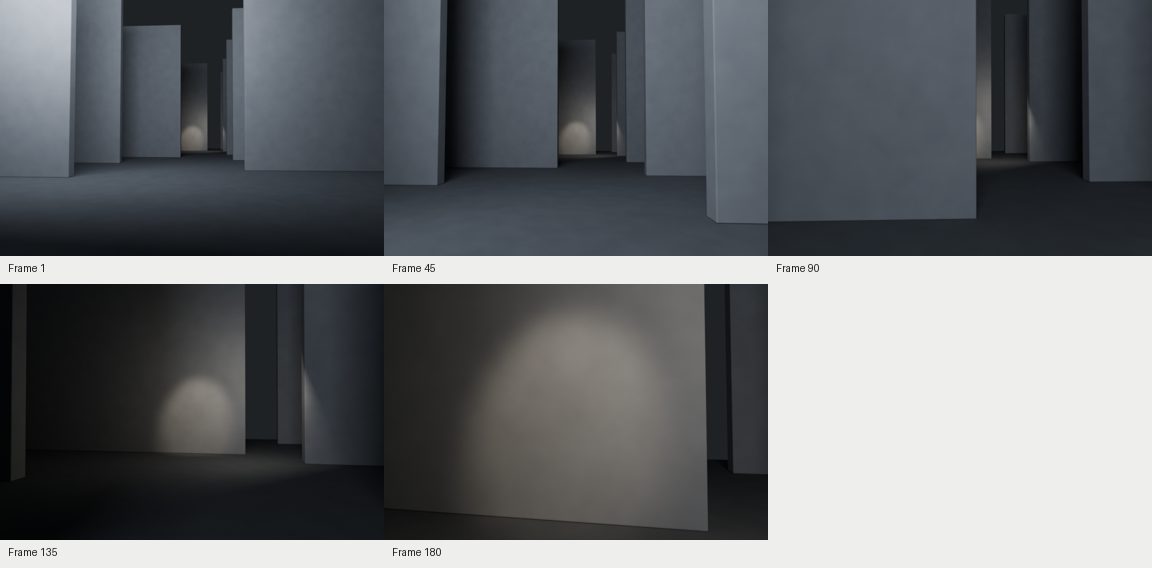


Evaluate: Evaluator is comparing actual image pixels with the fixed intention.



Design review: Design review completed; technical validity alone did not determine this judgment.


The sampled sequence convincingly establishes repetition, interrupts its alignment through occlusion, and returns to the anticipated light at closer range. Its strongest achievement is continuity: the same planar vocabulary carries both the commanding opening and the quieter ending, with no visible chamber change or spectacle. Measured camera positions support forward travel with lateral displacement, though hesitation and smooth pacing remain unverified. A focused material revision would strengthen the missing shift toward close attention: the ending currently enlarges the surface more clearly than it reveals it.

Scores / 5: intention preservation: 4; sequence readability: 4; transitions and pacing: 4; spatial composition: 4; visual legibility: 4

Preserved:
- Oversized repeated surfaces establish an order extending beyond the opening frame.
- The smaller illuminated interval is anticipated early, substantially concealed at the midpoint, and encountered again at closer range.
- The interruption operates through overlapping surfaces rather than collision, symbolic objects, or a visibly separate chamber.
- The restrained surface vocabulary and right-hand remnants of repetition connect the closing encounter to the opening order.
- Measured scene properties support one connected setting and a 180-frame, 12-fps camera shot.

Transformed:
- The distant luminous marker becomes a large soft gradient, shifting emphasis from navigating repeated edges toward attending to one nearby surface.
- The initially balanced passage becomes strongly asymmetric during concealment and remains asymmetrical in the clos


Spatial plan: Spatial plan passed the handoff checks.


...


Build: Designer is generating scene version 2.



Tool request: Build the specified continuous mineral-plane passage with static soft illumination and a single eased camera journey.



Tool observation: Blender returned its execution result.
Tool status: ok

Inspect: Checking scene version 2 against technical requirements.



Technical checks: Independent measurements returned.
Technical checks: passed
Planned measurements matched: 5 / 5

Preview: Rendering five ordered views of version 2.



Preview result: Preview render result.


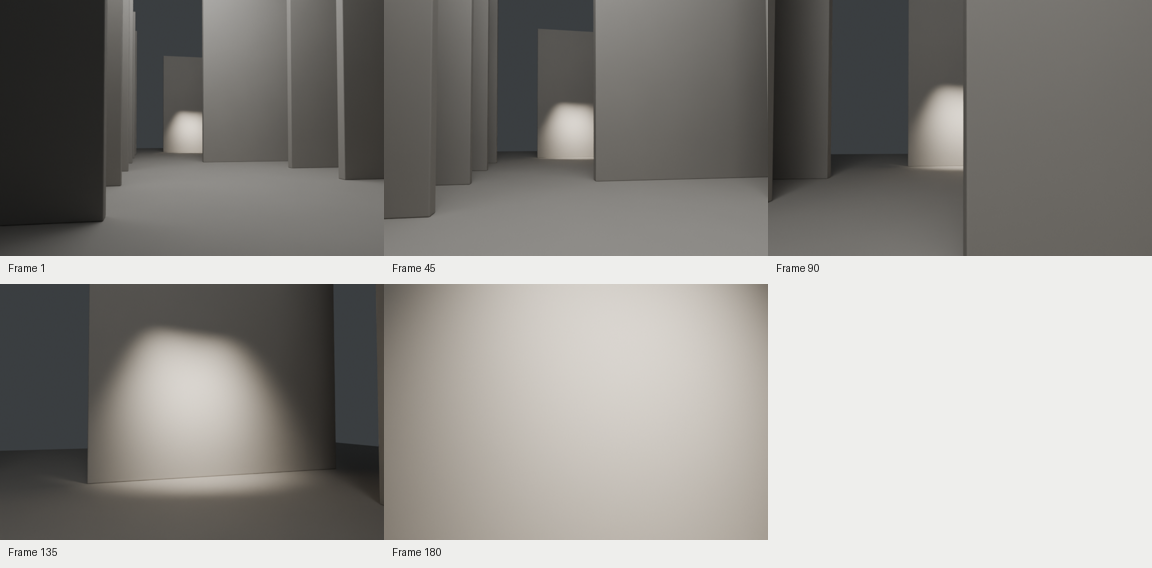


Evaluate: Evaluator is comparing actual image pixels with the fixed intention.



Design review: Design review completed; technical validity alone did not determine this judgment.


The opening convincingly establishes repetition, oversized surfaces, and an anticipated luminous interval. The sampled progression also supports an overlap followed by a reveal within one consistent setting. However, the light never visibly disappears in these samples, weakening the perceptual hinge. More decisively, the ending abandons spatial and material evidence: proximity produces a nearly blank image rather than intimate attention with monumentality still present. Targeted changes to the occlusion path, final framing, and close-range material legibility would preserve the existing strengths while recovering the intended ending.

Scores / 5: intention preservation: 3; sequence readability: 3; transitions and pacing: 3; spatial composition: 3; visual legibility: 3

Preserved:
- Opening repetition and surfaces extending beyond the frame support a commanding spatial order.
- The smaller illuminated interval is anticipated from the opening view.
- The overlap and subsequent reveal use the same restrained surface vocabulary rather than a separate spectacle.
- Measured scene properties support a connected setting and the specified 180-frame, 12-fps duration.

Transformed:
- The interruption reads primarily as progressive narrowing around a persistent light patch, rather than temporary concealment and rediscovery.
- Closing proximity becomes an almost abstract field of brightness instead of close attention to materially legible surfaces.

Lost:
- Recognizable traces of the larger order disappear in the final sampled view.
- The intended newly discernible surface texture is absent from the closing evidence.
- The bound


Final output: Animation export complete.
Export status: ok
Frames: 180 | Seconds: 15.0

Run result: complete | Selected version: 1
Build attempts: 2 | Design revisions: 1 | Model calls: 7


Watch the complete movement and pacing before judging the relation to the intention.
Remaining limitation: Design revision limit reached with unresolved feedback.


In [14]:
sequence_four = ['monumentality', 'interruption', 'intimacy']
result_four = await run_sequence(sequence_four, "04_monumentality_interruption_intimacy")